In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.append("../..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import xarray as xr

from cordex2energy.results.plotting import (
    plot_gmst_anomalies,
    plot_gmst_anomalies_subset_vs_all
)


sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [9]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])
path_data_gcm = Path("/net/atmos/data/cmip5-ng/")
path_data_cmip5 = Path("/net/atmos/data/cmip5/")

path_figs = Path("../../figs")
(path_figs / "driving_gcms").mkdir(parents=True, exist_ok=True)

# Load GCM data

In [4]:
gcms = ["CNRM-CM5_r1i1p1", "HadGEM2-ES_r1i1p1", "NorESM1-M_r1i1p1", "MPI-ESM-LR_r1i1p1", "EC-EARTH_r12i1p1"]
ensemble_members = [gcm.split("_")[-1] for gcm in gcms]
gcms = [gcm.split("_")[0] for gcm in gcms]

In [11]:
xr.open_dataset("/net/atmos/data/cmip5/historical/Amon/tas/CNRM-CM5/r1i1p1/tas_Amon_CNRM-CM5_historical_r1i1p1_185001-189912.nc")

<xarray.Dataset> Size: 79MB
Dimensions:    (time: 600, bnds: 2, lat: 128, lon: 256)
Coordinates:
  * time       (time) datetime64[ns] 5kB 1850-01-16T12:00:00 ... 1899-12-16T1...
  * lat        (lat) float64 1kB -88.93 -87.54 -86.14 ... 86.14 87.54 88.93
  * lon        (lon) float64 2kB 0.0 1.406 2.812 4.219 ... 355.8 357.2 358.6
    height     float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 10kB ...
    lat_bnds   (lat, bnds) float64 2kB ...
    lon_bnds   (lon, bnds) float64 4kB ...
    tas        (time, lat, lon) float32 79MB ...
Attributes: (12/28)
    institution:            CNRM (Centre National de Recherches Meteorologiqu...
    institute_id:           CNRM-CERFACS
    experiment_id:          historical
    source:                 CNRM-CM5 2010 Atmosphere: ARPEGE-Climat (V5.2.1, ...
    model_id:               CNRM-CM5
    forcing:                GHG, SA, Sl, Vl, BC, OC
    ...                     ...
    table_id:               Table Amon (31 January 2011) 53b766a395ac41696af4...
    title:                  CNRM-CM5 model output prepared for CMIP5 historical
    parent_experiment:      pre-industrial control
    modeling_realm:         atmos
    realization:            1
    cmor_version:           2.5.3

In [5]:
var = "tas"
temp_res = "ann"
scenarios = ["rcp26", "rcp45", "rcp85"]

subset_gcms = []
for gcm, ens in zip(gcms, ensemble_members):
    for scenario in scenarios:
        subset_gcms.extend(sorted(path_data_gcm.glob(f"{var}/*{temp_res}_{gcm}_{scenario}_*{ens}*_g025.nc")))

len(subset_gcms)

15

In [6]:
all_other_gcms_data = []
for scenario in scenarios:
    all_other_gcms_data.extend(
        sorted(path_data_gcm.glob(f"{var}/*{temp_res}*{scenario}_*_g025.nc"))
    )
# Remove all elements in matches from all_other_gcms_data
all_other_gcms_data = [item for item in all_other_gcms_data if item not in subset_gcms]
len(all_other_gcms_data)

251

# Plot

In [7]:
reference_period = slice("1871", "1900")

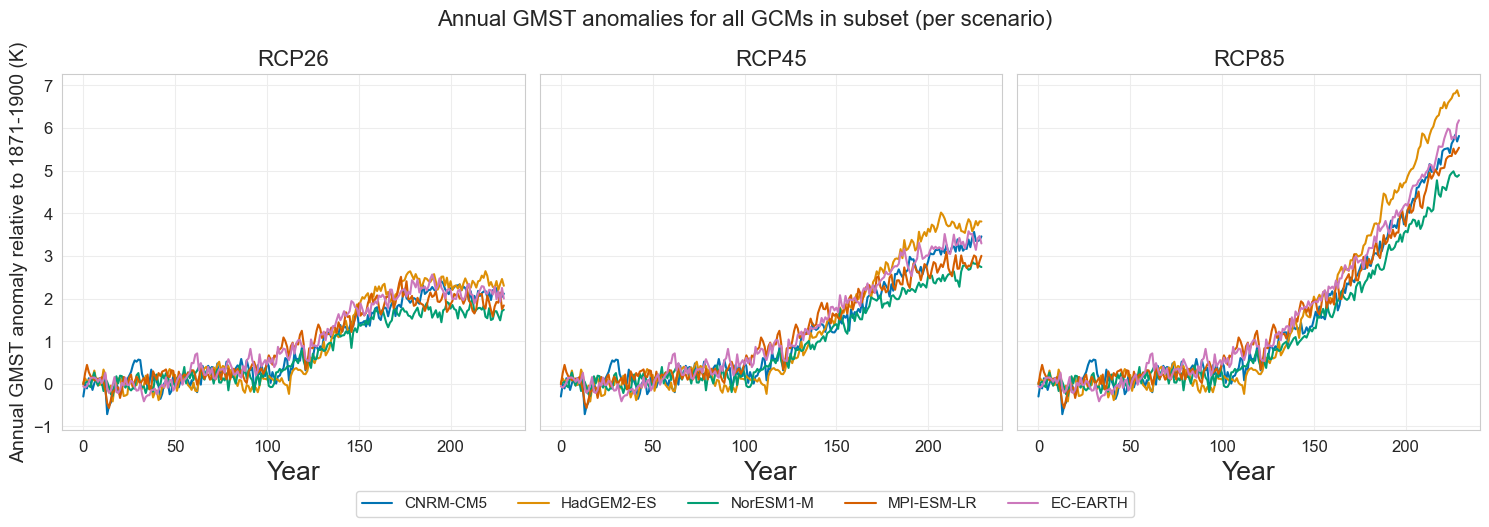

In [13]:
components_size_config = {
    "FONTSIZE_LEGEND": 11,
    "FONTSIZE_TICKS": 12,
    "FONTSIZE_LABELS": 14,
    "FONTSIZE_TITLE": 16,
}

plot_gmst_anomalies(
    scenarios=scenarios,
    subset_gcms=subset_gcms,
    var=var,
    reference_period=reference_period,
    time_dim="time",
    figsize=(15, 5),
    components_size_config=components_size_config,
    path_savefig=path_figs / "driving_gcms" / "annual_gmst_subset_anomalies.png"
)

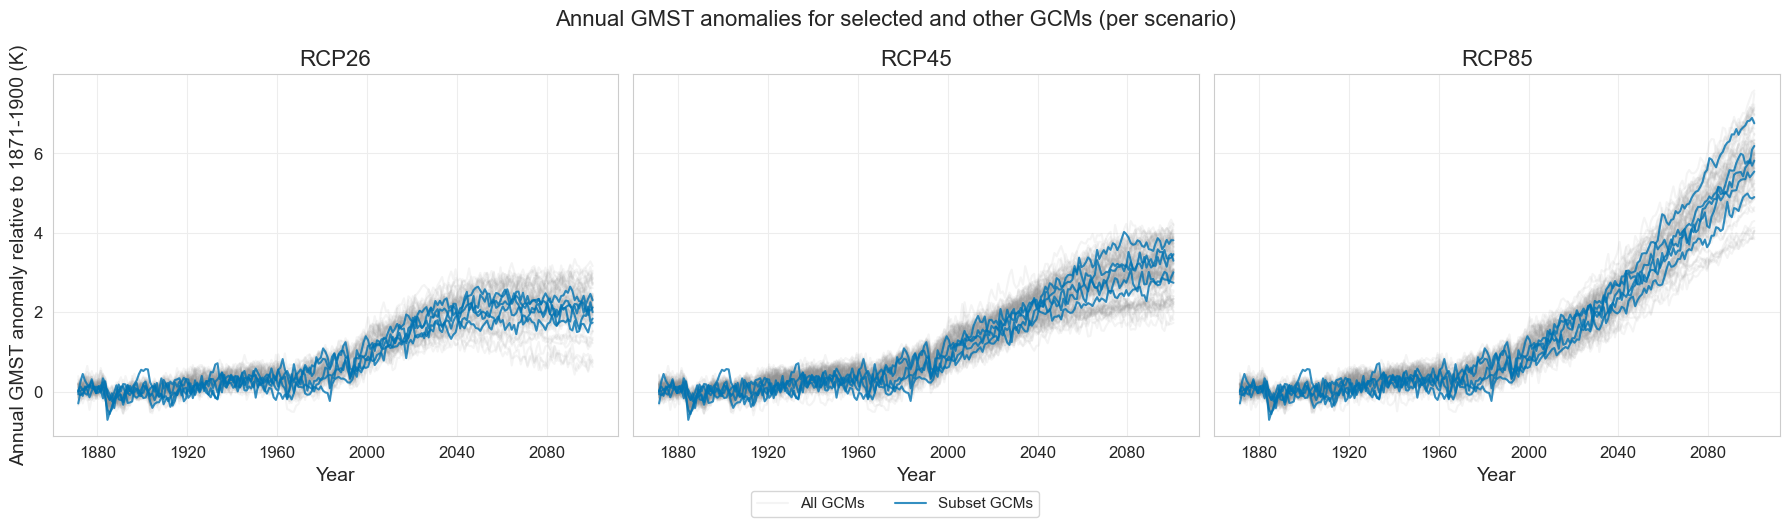

In [14]:
plot_gmst_anomalies_subset_vs_all(
    scenarios=scenarios,
    subset_gcms=subset_gcms,
    all_other_gcms_data=all_other_gcms_data,
    var=var,
    reference_period=reference_period,
    components_size_config=components_size_config,
    time_dim="year",
    figsize=(18, 5),
    # path_savefig=path_figs / "driving_gcms" / "annual_gmst_all_gcms_anomalies_individual_subset.png"
    separate_subset=False
)

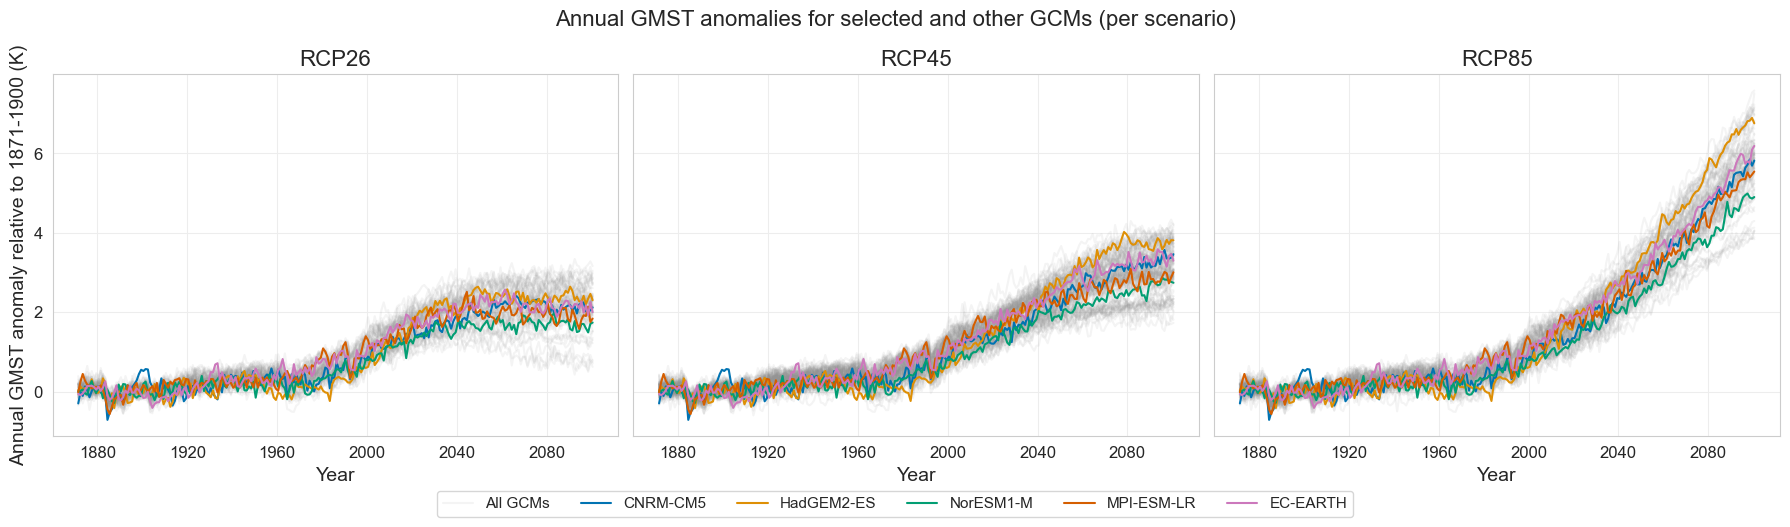

In [15]:
plot_gmst_anomalies_subset_vs_all(
    scenarios=scenarios,
    subset_gcms=subset_gcms,
    all_other_gcms_data=all_other_gcms_data,
    var=var,
    reference_period=reference_period,
    time_dim="year",
    figsize=(18, 5),
    components_size_config=components_size_config,
    path_savefig=path_figs / "driving_gcms" / "annual_gmst_all_gcms_anomalies_individual_subset.png",
    separate_subset=True
)

# Global Warming Levels

Warming-level periods are read directly from the pre-computed file
`cmip5_warming_levels_all_ens_1850_1900.yml` (Mathias Hauser, 2024-04-22).
Reference baseline: **1861–1900**.

For each model/scenario the file stores the 20-year window (`start_year`–`end_year`)
centred on the first year where the 20-year running-mean GMST anomaly first exceeded
the threshold.  `central_year = start_year + 10`.

> **Note:** HadGEM2-ES is absent from this file (will show `—`).
> NorESM1-M does not reach 1.5 °C under rcp26.

In [22]:
from cordex2energy.results.analysis import load_warming_level_periods

warming_levels = [1.5, 2.0, 3.0]
_gcm_ens = dict(zip(gcms, ensemble_members))  # {"CNRM-CM5": "r1i1p1", ...}

df_gwl = load_warming_level_periods(
    yml_path=path_data_processed / "cmip5_warming_levels_all_ens_1850_1900.yml",
    warming_levels=warming_levels,
    gcms=_gcm_ens,
)

# Also keep the nested dict (gwl_results) so the display cell below still works
gwl_results = {}
for gcm in gcms:
    gwl_results[gcm] = {}
    for scenario in scenarios:
        gwl_results[gcm][scenario] = {}
        for wl in warming_levels:
            row = df_gwl.query(
                "model == @gcm and scenario == @scenario and warming_level == @wl"
            )
            gwl_results[gcm][scenario][wl] = (
                row[["start_year", "end_year", "central_year"]].iloc[0].to_dict()
                if not row.empty else None
            )

df_gwl

[{'model': 'CNRM-CM5', 'ensemble': 'r1i1p1', 'scenario': 'rcp26', 'warming_level': 1.5, 'start_year': 2034, 'end_year': 2053, 'central_year': 2044}, {'model': 'EC-EARTH', 'ensemble': 'r12i1p1', 'scenario': 'rcp26', 'warming_level': 1.5, 'start_year': 2014, 'end_year': 2033, 'central_year': 2024}, {'model': 'MPI-ESM-LR', 'ensemble': 'r1i1p1', 'scenario': 'rcp26', 'warming_level': 1.5, 'start_year': 2013, 'end_year': 2032, 'central_year': 2023}, {'model': 'CNRM-CM5', 'ensemble': 'r1i1p1', 'scenario': 'rcp45', 'warming_level': 1.5, 'start_year': 2028, 'end_year': 2047, 'central_year': 2038}, {'model': 'EC-EARTH', 'ensemble': 'r12i1p1', 'scenario': 'rcp45', 'warming_level': 1.5, 'start_year': 2013, 'end_year': 2032, 'central_year': 2023}, {'model': 'MPI-ESM-LR', 'ensemble': 'r1i1p1', 'scenario': 'rcp45', 'warming_level': 1.5, 'start_year': 2013, 'end_year': 2032, 'central_year': 2023}, {'model': 'NorESM1-M', 'ensemble': 'r1i1p1', 'scenario': 'rcp45', 'warming_level': 1.5, 'start_year': 203

,model,ensemble,scenario,warming_level,start_year,end_year,central_year
0,CNRM-CM5,r1i1p1,rcp26,1.5,2034,2053,2044
1,CNRM-CM5,r1i1p1,rcp45,1.5,2028,2047,2038
2,CNRM-CM5,r1i1p1,rcp45,2.0,2049,2068,2059
3,CNRM-CM5,r1i1p1,rcp85,1.5,2021,2040,2031
4,CNRM-CM5,r1i1p1,rcp85,2.0,2036,2055,2046
5,CNRM-CM5,r1i1p1,rcp85,3.0,2058,2077,2068
6,EC-EARTH,r12i1p1,rcp26,1.5,2014,2033,2024
7,EC-EARTH,r12i1p1,rcp45,1.5,2013,2032,2023
8,EC-EARTH,r12i1p1,rcp45,2.0,2035,2054,2045
9,EC-EARTH,r12i1p1,rcp85,1.5,2009,2028,2019


In [19]:
import pandas as pd

rows = []
for gcm in gcms:
    for scenario in scenarios:
        for wl in warming_levels:
            r = gwl_results.get(gcm, {}).get(scenario, {}).get(wl)
            if r is not None:
                label = f"{r['central_year']}  ({r['start_year']}–{r['end_year']})"
            else:
                label = "—"
            rows.append({"GCM": gcm, "Scenario": scenario, "WL": f"+{wl} °C", "value": label})

df = pd.DataFrame(rows)
df_table = df.pivot_table(index=["GCM", "Scenario"], columns="WL", values="value", aggfunc="first")
# Ensure columns are sorted by warming level
df_table = df_table[[f"+{wl} °C" for wl in warming_levels]]
df_table

WL                             +1.0 °C            +1.5 °C            +2.0 °C  \
GCM        Scenario                                                            
CNRM-CM5   rcp26     2014  (2004–2023)  2044  (2034–2053)                  —   
           rcp45     2013  (2003–2022)  2038  (2028–2047)  2060  (2050–2069)   
           rcp85     2013  (2003–2022)  2032  (2022–2041)  2046  (2036–2055)   
EC-EARTH   rcp26     2004  (1994–2013)  2026  (2016–2035)                  —   
           rcp45     2005  (1995–2014)  2025  (2015–2034)  2046  (2036–2055)   
           rcp85     2005  (1995–2014)  2019  (2009–2028)  2036  (2026–2045)   
HadGEM2-ES rcp26     2012  (2002–2021)  2025  (2015–2034)                  —   
           rcp45     2013  (2003–2022)  2030  (2020–2039)  2046  (2036–2055)   
           rcp85     2011  (2001–2020)  2025  (2015–2034)  2037  (2027–2046)   
MPI-ESM-LR rcp26     2004  (1994–2013)  2023  (2013–2032)                  —   
           rcp45     2003  (1993–2012)  2022  (2012–2031)  2043  (2033–2052)   
           rcp85     2003  (1993–2012)  2017  (2007–2026)  2036  (2026–2045)   
NorESM1-M  rcp26     2018  (2008–2027)                  —                  —   
           rcp45     2019  (2009–2028)  2041  (2031–2050)  2075  (2065–2084)   
           rcp85     2018  (2008–2027)  2034  (2024–2043)  2050  (2040–2059)   

WL                             +3.0 °C  
GCM        Scenario                     
CNRM-CM5   rcp26                     —  
           rcp45                     —  
           rcp85     2069  (2059–2078)  
EC-EARTH   rcp26                     —  
           rcp45                     —  
           rcp85     2062  (2052–2071)  
HadGEM2-ES rcp26                     —  
           rcp45                     —  
           rcp85     2056  (2046–2065)  
MPI-ESM-LR rcp26                     —  
           rcp45                     —  
           rcp85     2061  (2051–2070)  
NorESM1-M  rcp26                     —  
           rcp45                     —  
           rcp85     2074  (2064–2083)